In [95]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
os.makedirs("charts", exist_ok=True)

SOURCE = "Source: Our World in Data / Global Carbon Project"
RED, BLUE, ORANGE, GREEN, GREY = "#C0392B", "#2E86C1", "#E67E22", "#27AE60", "#B0B7BC"

def finish(name):
    """Add source note, save at 200 dpi, show."""
    plt.figtext(0.01, -0.02, SOURCE, fontsize=8, color="gray", ha="left")
    plt.savefig(f"charts/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [96]:
df = pd.read_csv("https://catalog.ourworldindata.org/emissions/owid_co2/owid_co2.csv")

In [97]:
print(df.shape)
display(df.head())
display(df.tail())

(56269, 79)


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_energy_supply,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_energy_supply,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
56264,Zimbabwe,2021,ZWE,15797220.0,2.514009e+10,0.424781,0.026890,10.130522,1.695750,20.104277,...,0.104508,0.000527,0.000977,0.001677,0.000173,36.871010,27.906528,16.408270,3.564955,35.190240
56265,Zimbabwe,2022,ZWE,16069061.0,2.590159e+10,0.363114,0.022597,12.256476,2.125954,20.985626,...,0.103672,0.000531,0.000982,0.001689,0.000176,57.510273,29.916828,18.830246,2.557080,20.863092
56266,Zimbabwe,2023,ZWE,16340829.0,NaN,0.403459,0.024690,15.096099,2.839623,23.168350,...,0.102958,0.000536,0.000988,0.001703,0.000178,53.661930,31.028685,20.318186,1.039066,6.883010
56267,Zimbabwe,2024,ZWE,16634366.0,NaN,0.403459,0.024255,15.206696,0.110598,0.732625,...,0.102267,0.000542,0.000994,0.001716,0.000180,67.522835,31.066437,20.773445,0.930072,6.116200
56268,Zimbabwe,2025,ZWE,16950798.0,NaN,0.403459,0.023802,17.348314,2.141617,14.083385,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [98]:
countries = df[df["iso_code"].notna() & ~df["iso_code"].astype(str).str.startswith("OWID")].copy()
world = df[df["country"] == "World"].copy()

# Pinned on purpose: 2022 is the last year with complete country + GDP data
latest = 2022
gdp_year = 2022

countries["gdp_per_capita"] = countries["gdp"] / countries["population"]

# One fixed colour per top-5 emitter, reused in every chart
top5 = countries[countries["year"] == latest].nlargest(5, "co2")["country"].tolist()
palette = dict(zip(top5, [RED, BLUE, ORANGE, GREEN, "#8E44AD"]))

n_ok = countries[countries["year"] == latest]["co2"].notna().sum()
print(f"Chart year: {latest} | countries with CO2 data: {n_ok} | top 5: {top5}")

Chart year: 2022 | countries with CO2 data: 220 | top 5: ['China', 'United States', 'India', 'Russia', 'Japan']


## Chart: Line chart


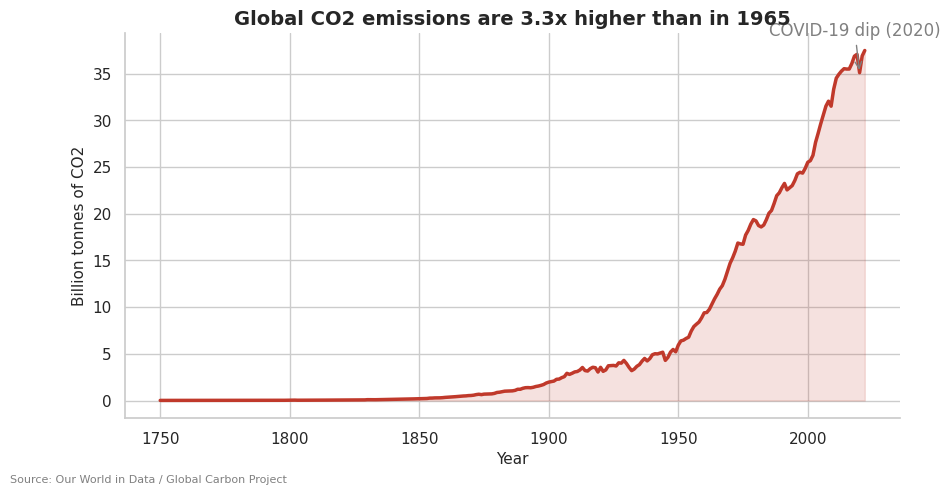

In [99]:
w = world[world["year"] <= latest].dropna(subset=["co2"])
growth_x = w.loc[w["year"] == latest, "co2"].iloc[0] / w.loc[w["year"] == 1965, "co2"].iloc[0]

fig, ax = plt.subplots()
ax.plot(w["year"], w["co2"] / 1000, color=RED, linewidth=2.5)
ax.fill_between(w["year"], w["co2"] / 1000, color=RED, alpha=0.15)

y2020 = w.loc[w["year"] == 2020, "co2"].iloc[0] / 1000
ax.annotate("COVID-19 dip (2020)", xy=(2020, y2020), xytext=(1985, y2020 + 4),
            arrowprops=dict(arrowstyle="->", color="gray"), color="gray")

ax.set_title(f"Global CO2 emissions are {growth_x:.1f}x higher than in 1965")
ax.set_ylabel("Billion tonnes of CO2")
ax.set_xlabel("Year")
finish("01_global_trend")

Global emissions have risen in almost every year since 1965, with only short dips, such as 2020 (COVID-19).

## Chart: Multi-line chart

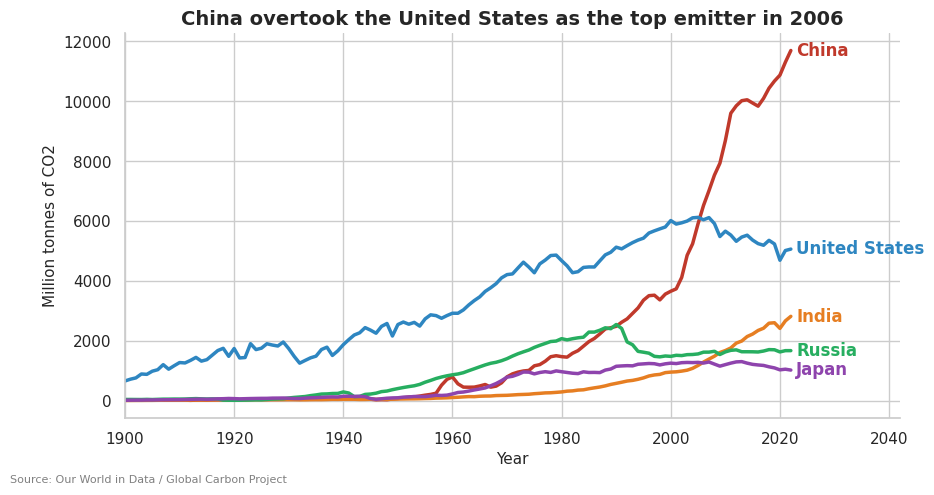

In [100]:
data = countries[countries["country"].isin(top5) & countries["year"].between(1900, latest)]
piv = data.pivot(index="year", columns="country", values="co2")
cross = int((piv["China"] > piv["United States"]).idxmax())

fig, ax = plt.subplots()
for c in top5:
    d = data[data["country"] == c].dropna(subset=["co2"])
    ax.plot(d["year"], d["co2"], color=palette[c], linewidth=2.5)
    ax.text(d["year"].max() + 1, d["co2"].iloc[-1], c, color=palette[c],
            va="center", fontweight="bold")
ax.set_xlim(1900, latest + 20)

ax.set_title(f"China overtook the United States as the top emitter in {cross}")
ax.set_ylabel("Million tonnes of CO2")
ax.set_xlabel("Year")
finish("02_top5_trend")

China's emissions surged after 2000 and passed the United States in the mid-2000s, while US emissions have slowly declined.

## Chart: Bar chart

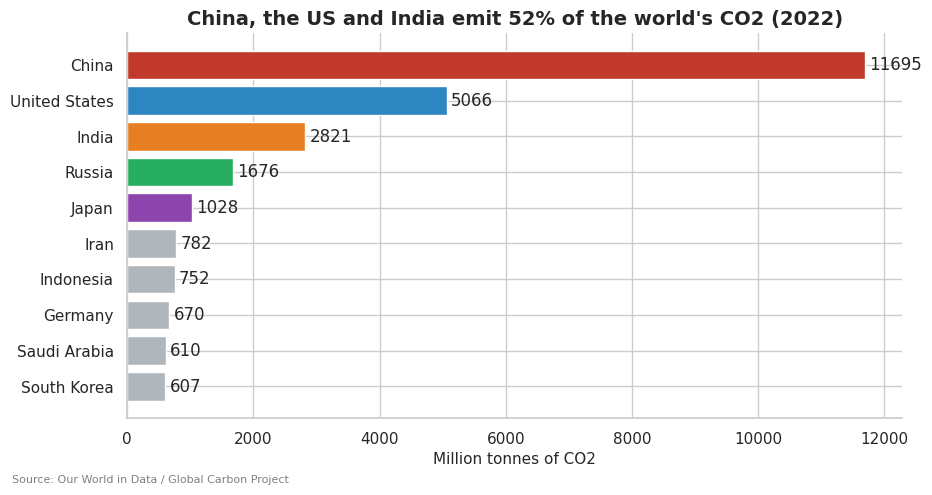

In [101]:
world_now = world.loc[world["year"] == latest, "co2"].iloc[0]
top10 = countries[countries["year"] == latest].nlargest(10, "co2")
share3 = top10["co2"].head(3).sum() / world_now * 100

fig, ax = plt.subplots()
rev = top10.iloc[::-1]
bars = ax.barh(rev["country"], rev["co2"], color=[palette.get(c, GREY) for c in rev["country"]])
ax.bar_label(bars, fmt="%.0f", padding=3)

ax.set_title(f"China, the US and India emit {share3:.0f}% of the world's CO2 ({latest})")
ax.set_xlabel("Million tonnes of CO2")
finish("03_top10_emitters")

China, the US and India together emit roughly half of the world's CO₂. Every other country in the top 10 emits far less.

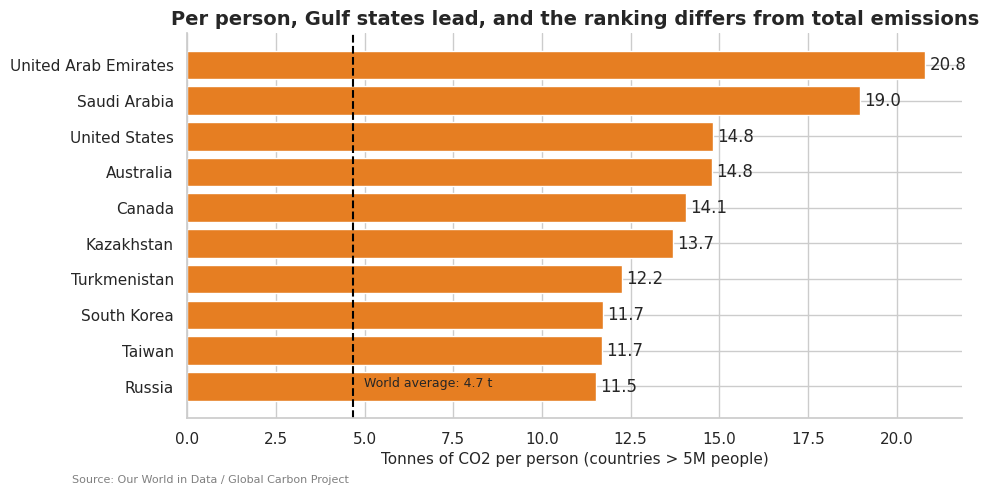

In [102]:
big = countries[(countries["year"] == latest) & (countries["population"] > 5_000_000)]
top_pc = big.nlargest(10, "co2_per_capita")
world_avg = world.loc[world["year"] == latest, "co2_per_capita"].iloc[0]

fig, ax = plt.subplots()
rev = top_pc.iloc[::-1]
bars = ax.barh(rev["country"], rev["co2_per_capita"], color=ORANGE)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.axvline(world_avg, color="black", linestyle="--")
ax.text(world_avg + 0.3, 0, f"World average: {world_avg:.1f} t", fontsize=9)

ax.set_title("Per person, Gulf states lead, and the ranking differs from total emissions")
ax.set_xlabel("Tonnes of CO2 per person (countries > 5M people)")
finish("04_top10_per_person")

Per person, Gulf and oil-producing countries lead, so this ranking looks very different from total emissions. The dashed line is the world average.

## Chart: Scatter plot

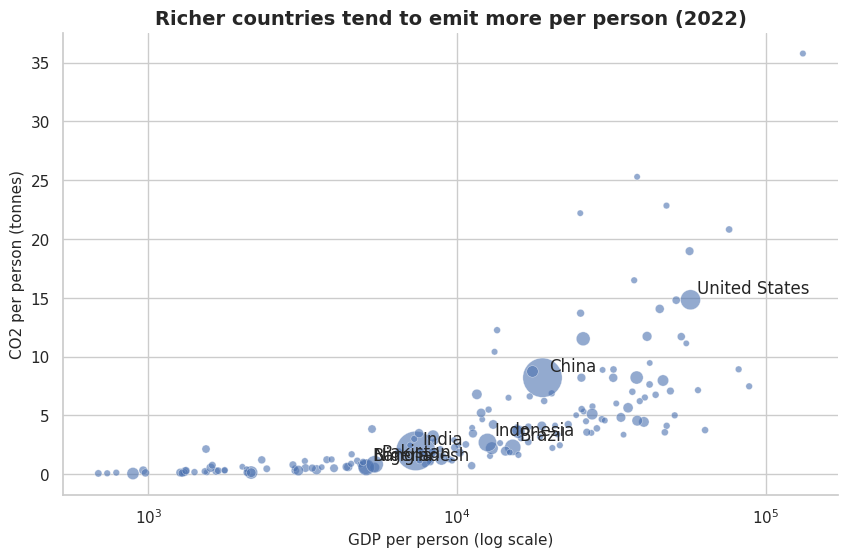

In [103]:
s = countries[countries["year"] == gdp_year].dropna(subset=["gdp_per_capita", "co2_per_capita", "population"])

plt.figure(figsize=(10, 6))
sns.scatterplot(data=s, x="gdp_per_capita", y="co2_per_capita",
                size="population", sizes=(20, 800), alpha=0.6, legend=False)
plt.xscale("log")
for _, r in s.nlargest(8, "population").iterrows():
    plt.annotate(r["country"], (r["gdp_per_capita"], r["co2_per_capita"]), xytext=(5, 5), textcoords="offset points")

plt.title(f"Richer countries tend to emit more per person ({gdp_year})")
plt.xlabel("GDP per person (log scale)")
plt.ylabel("CO2 per person (tonnes)")

plt.savefig("charts/05_gdp_vs_co2.png", dpi=200, bbox_inches="tight")
plt.show()

Richer countries generally emit more per person, but there are clear exceptions. Bubble size shows population

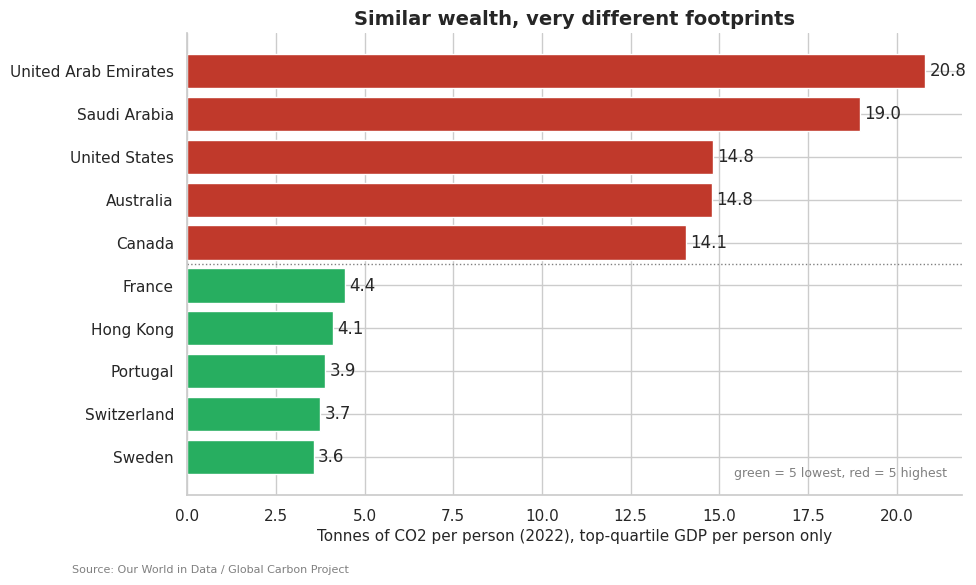

In [115]:
rich = s[(s["population"] > 5_000_000) &
         (s["gdp_per_capita"] >= s["gdp_per_capita"].quantile(0.75))].sort_values("co2_per_capita")

# Plot only the 5 lowest and 5 highest emitters
plot_df = pd.concat([rich.head(5), rich.tail(5)])
cut = len(rich.head(5))

fig, ax = plt.subplots(figsize=(10, 6))
colors_bar = [GREEN] * 5 + [RED] * 5
bars = ax.barh(plot_df["country"], plot_df["co2_per_capita"], color=colors_bar)
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.axhline(4.5, color="gray", linestyle=":", linewidth=1)

ax.set_title("Similar wealth, very different footprints")
ax.set_xlabel(f"Tonnes of CO2 per person ({gdp_year}), top-quartile GDP per person only")
ax.text(0.98, 0.04, "green = 5 lowest, red = 5 highest", transform=ax.transAxes,
        ha="right", fontsize=9, color="gray")
finish("05b_rich_but_efficient")

## Chart: Histogram

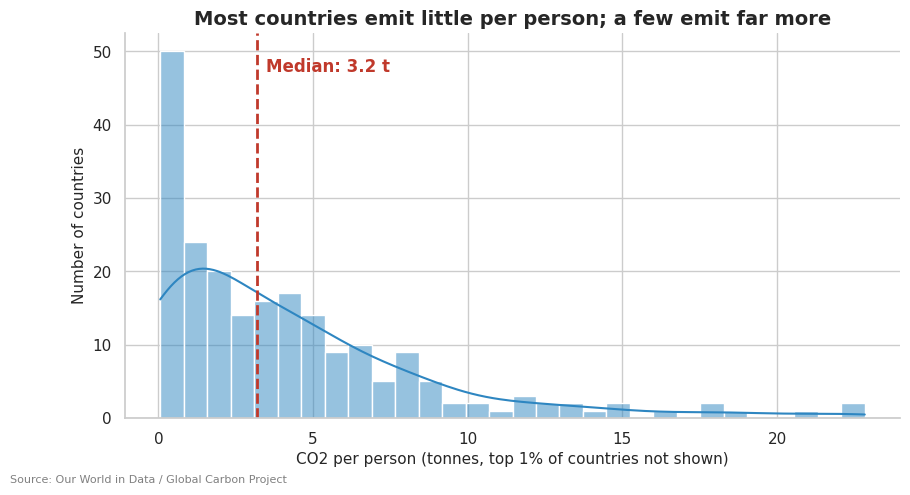

In [105]:
pc = countries[countries["year"] == latest]["co2_per_capita"].dropna()
pc_small = pc[pc <= pc.quantile(0.99)]

fig, ax = plt.subplots()
sns.histplot(pc_small, bins=30, kde=True, color=BLUE, ax=ax)
ax.axvline(pc.median(), color=RED, linestyle="--", linewidth=2)
ax.text(pc.median() + 0.3, ax.get_ylim()[1] * 0.9, f"Median: {pc.median():.1f} t",
        color=RED, fontweight="bold")

ax.set_title("Most countries emit little per person; a few emit far more")
ax.set_xlabel("CO2 per person (tonnes, top 1% of countries not shown)")
ax.set_ylabel("Number of countries")
finish("06_distribution")

Most countries emit only a few tonnes per person, while a small group emits far more. The red line marks the median.

## Chart: Heatmap

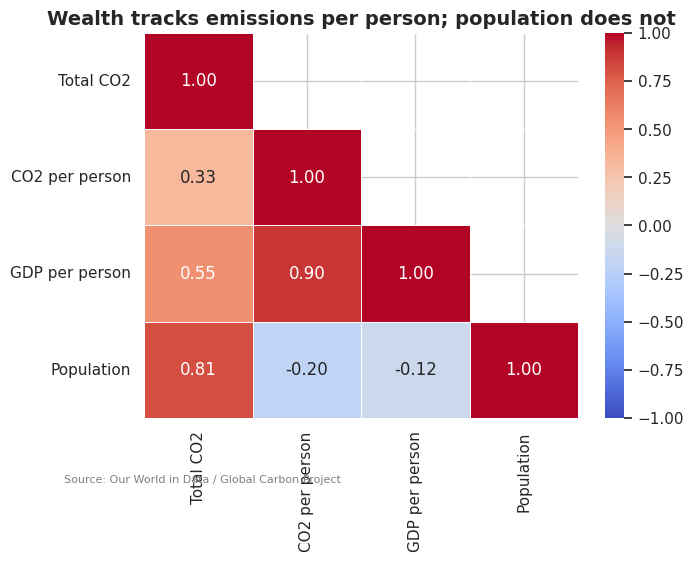

In [106]:
labels = {"co2": "Total CO2", "co2_per_capita": "CO2 per person",
          "gdp_per_capita": "GDP per person", "population": "Population"}
corr = (countries[countries["year"] == gdp_year][list(labels)]
        .corr(method="spearman").rename(index=labels, columns=labels))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Wealth tracks emissions per person; population does not")
finish("07_heatmap")

GDP per person is positively related to CO₂ per person, while population size is not (Spearman rank correlation, 2022).

## Chart: Stacked area

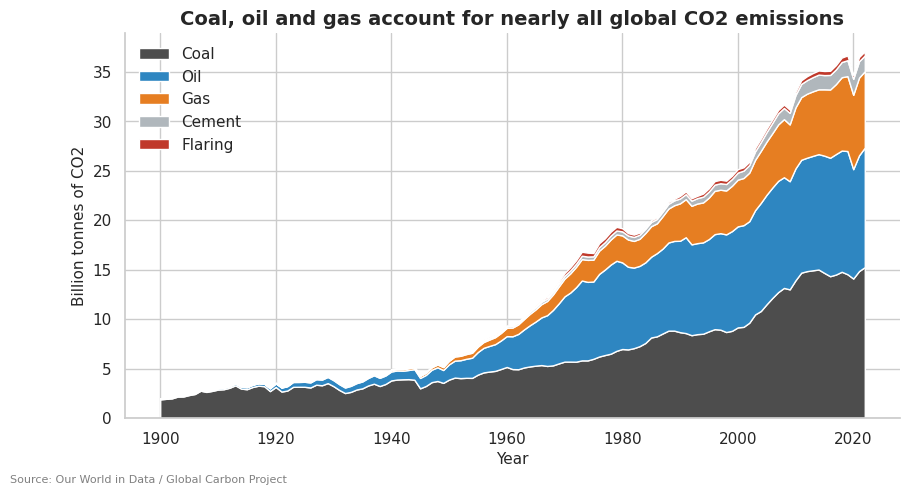

In [107]:
src = ["coal_co2", "oil_co2", "gas_co2", "cement_co2", "flaring_co2"]
names = ["Coal", "Oil", "Gas", "Cement", "Flaring"]
colors = ["#4D4D4D", BLUE, ORANGE, GREY, RED]

ws = world[world["year"].between(1900, latest)].set_index("year")[src].dropna(how="all")

fig, ax = plt.subplots()
ax.stackplot(ws.index, [ws[c].fillna(0) / 1000 for c in src], labels=names, colors=colors)
ax.legend(loc="upper left", frameon=False)

ax.set_title("Coal, oil and gas account for nearly all global CO2 emissions")
ax.set_ylabel("Billion tonnes of CO2")
ax.set_xlabel("Year")
finish("08_by_source")

Coal, oil and gas account for nearly all global CO₂. Coal and oil have long dominated, and gas has grown steadily.

## Chart: Donut chart

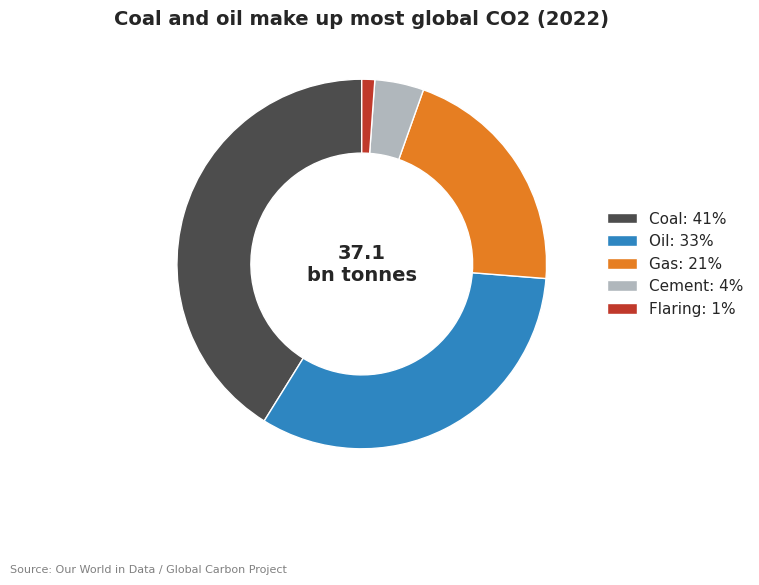

In [108]:
values = ws.loc[latest].fillna(0)

fig, ax = plt.subplots(figsize=(7, 6))
wedges, _ = ax.pie(values, startangle=90, colors=colors,
                   wedgeprops=dict(width=0.4, edgecolor="white"))
ax.legend(wedges, [f"{n}: {v / values.sum() * 100:.0f}%" for n, v in zip(names, values)],
          loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
ax.text(0, 0, f"{values.sum() / 1000:.1f}\nbn tonnes", ha="center", va="center",
        fontsize=14, fontweight="bold")

ax.set_title(f"Coal and oil make up most global CO2 ({latest})")
finish("09_source_share")

Coal and oil together make up roughly three-quarters of global CO₂ emissions.

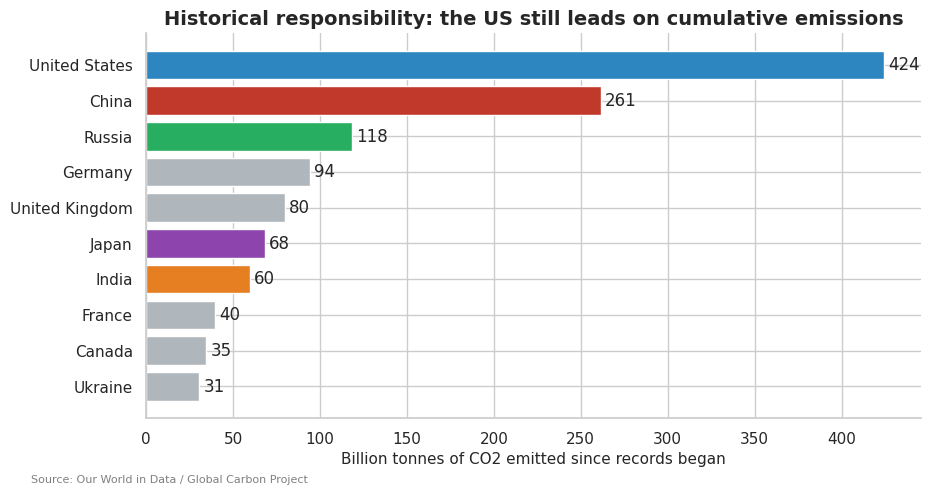

In [109]:
cum10 = countries[countries["year"] == latest].nlargest(10, "cumulative_co2")

fig, ax = plt.subplots()
rev = cum10.iloc[::-1]
bars = ax.barh(rev["country"], rev["cumulative_co2"] / 1000,
               color=[palette.get(c, GREY) for c in rev["country"]])
ax.bar_label(bars, fmt="%.0f", padding=3)

ax.set_title("Historical responsibility: the US still leads on cumulative emissions")
ax.set_xlabel("Billion tonnes of CO2 emitted since records began")
finish("09b_cumulative")

## Chart: World map

In [110]:
m = countries[countries["year"] == latest]

fig = px.choropleth(m, locations="iso_code", color="co2_per_capita",
                    hover_name="country", color_continuous_scale="YlOrRd",
                    range_color=(0, m["co2_per_capita"].quantile(0.95)),
                    projection="natural earth",
                    labels={"co2_per_capita": "t CO2 per person"},
                    title=f"CO2 per person by country ({latest})")
fig.write_html("charts/10_world_map.html")
fig.show()

Per-person emissions vary widely between countries. The colour scale is capped at the 95th percentile so a few extreme values don't wash out the rest of the map.

## Chart: Animated chart

In [111]:
a = countries[(countries["year"] >= 1990) & (countries["year"] <= gdp_year)]
a = a.dropna(subset=["gdp_per_capita", "co2_per_capita", "population"]).sort_values("year")

fig = px.scatter(a, x="gdp_per_capita", y="co2_per_capita", size="population",
                 hover_name="country", animation_frame="year", log_x=True, size_max=50,
                 range_y=[0, a["co2_per_capita"].quantile(0.99)],
                 range_x=[a["gdp_per_capita"].min(), a["gdp_per_capita"].max()],
                 labels={"gdp_per_capita": "GDP per person (log)", "co2_per_capita": "t CO2 per person"},
                 template="plotly_white",
                 title="Wealth vs emissions per person, 1990 onwards")
fig.write_html("charts/11_animation.html")
fig.show()

In [112]:
names10 = countries[countries["year"] == latest].nlargest(10, "co2")["country"]
d10 = countries[countries["country"].isin(names10) & countries["year"].between(1950, latest)]
fig2 = px.line(d10, x="year", y="co2", color="country", template="plotly_white",
               labels={"co2": "Million tonnes of CO2"},
               title="Top 10 emitters since 1950 (hover to compare)")
fig2.update_traces(line_width=2.5)
fig2.update_layout(hovermode="x unified")
fig2.write_html("charts/11b_top10_interactive.html")
fig2.show()

Press play or drag the slider. Most countries move right (richer) over time, and many also move up (more CO₂ per person), but some wealthy countries have flattened or fallen. The line chart above lets you hover to compare the top 10 emitters.

## Dashboard

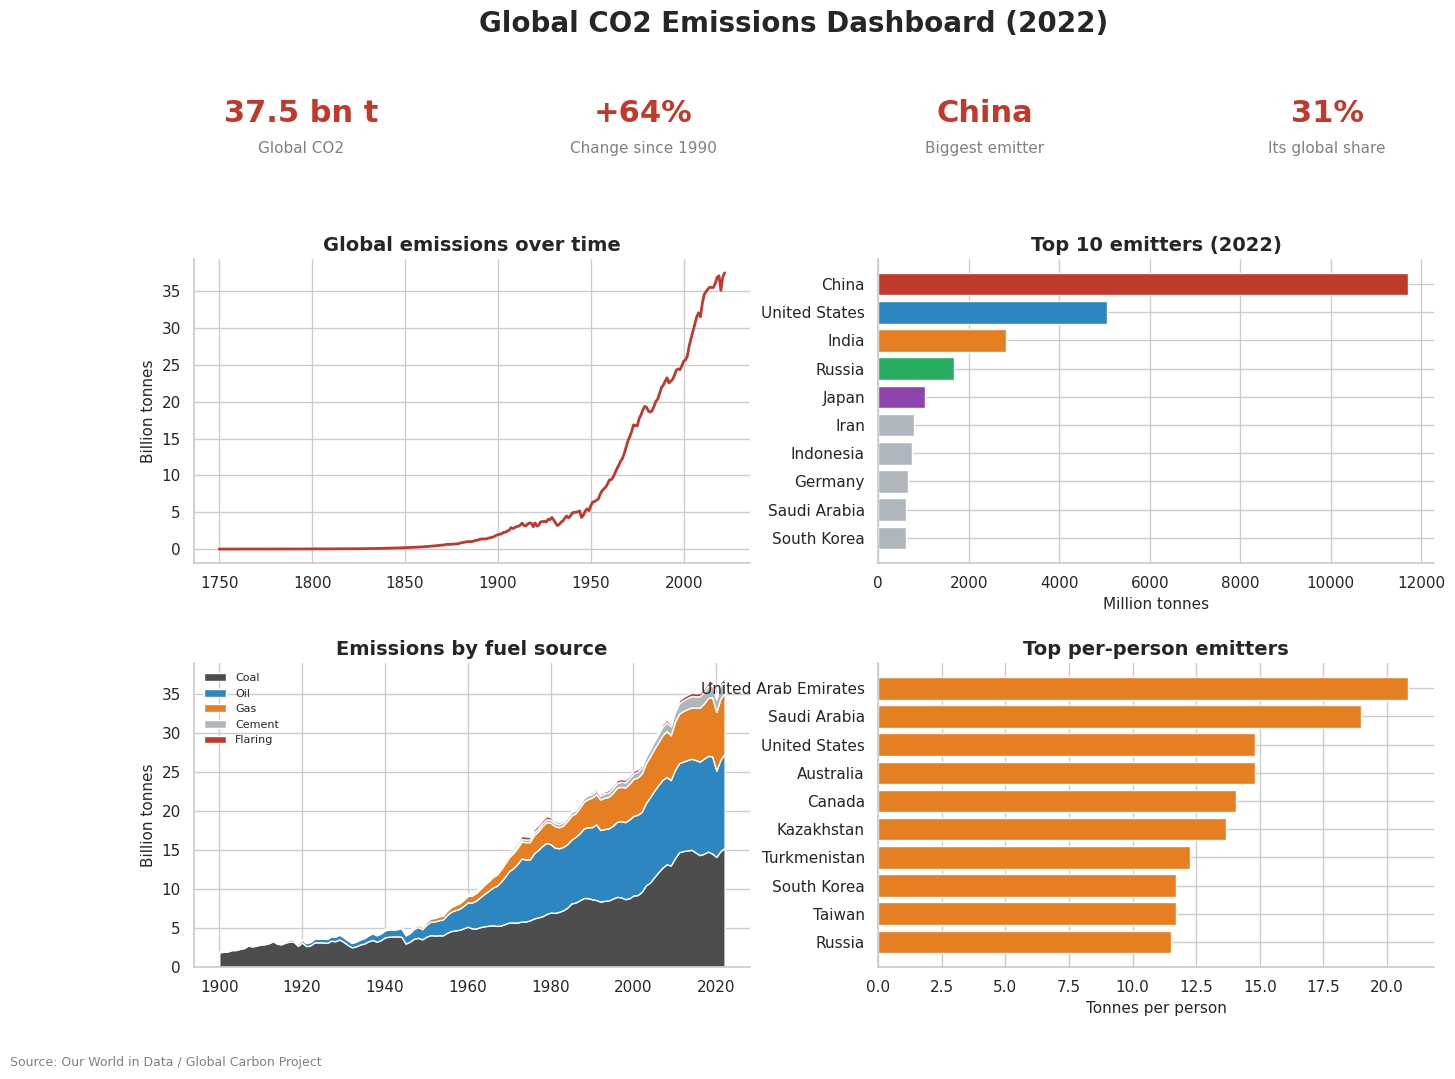

In [113]:
growth90 = (world_now / world.loc[world["year"] == 1990, "co2"].iloc[0] - 1) * 100
top1 = top10.iloc[0]

kpis = [
    ("Global CO2", f"{world_now / 1000:.1f} bn t"),
    ("Change since 1990", f"+{growth90:.0f}%"),
    ("Biggest emitter", top1["country"]),
    ("Its global share", f"{top1['co2'] / world_now * 100:.0f}%"),
]

fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(3, 4, height_ratios=[0.4, 2, 2], hspace=0.45, wspace=0.6, top=0.90)
fig.suptitle(f"Global CO2 Emissions Dashboard ({latest})", fontsize=20, fontweight="bold")

# KPI cards
for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.text(0.5, 0.6, value, ha="center", fontsize=22, fontweight="bold", color=RED)
    ax.text(0.5, 0.1, label, ha="center", fontsize=11, color="gray")

# 1) Global trend
ax1 = fig.add_subplot(gs[1, 0:2])
ax1.plot(w["year"], w["co2"] / 1000, color=RED, linewidth=2)
ax1.set_title("Global emissions over time"); ax1.set_ylabel("Billion tonnes")

# 2) Top 10 emitters
ax2 = fig.add_subplot(gs[1, 2:4])
r = top10.iloc[::-1]
ax2.barh(r["country"], r["co2"], color=[palette.get(c, GREY) for c in r["country"]])
ax2.set_title(f"Top 10 emitters ({latest})"); ax2.set_xlabel("Million tonnes")

# 3) Fuel sources
ax3 = fig.add_subplot(gs[2, 0:2])
ax3.stackplot(ws.index, [ws[c].fillna(0) / 1000 for c in src], labels=names, colors=colors)
ax3.legend(loc="upper left", frameon=False, fontsize=8)
ax3.set_title("Emissions by fuel source"); ax3.set_ylabel("Billion tonnes")

# 4) Per person
ax4 = fig.add_subplot(gs[2, 2:4])
r = top_pc.iloc[::-1]
ax4.barh(r["country"], r["co2_per_capita"], color=ORANGE)
ax4.set_title("Top per-person emitters"); ax4.set_xlabel("Tonnes per person")

plt.figtext(0.01, 0.02, SOURCE, fontsize=9, color="gray")
plt.savefig("charts/12_dashboard.png", dpi=200, bbox_inches="tight")
plt.show()

Together these charts show who emits, how much, and from which sources.

## Data Story

In [114]:
now = countries[countries["year"] == latest]
world_1990 = world.loc[world["year"] == 1990, "co2"].iloc[0]
growth = (world_now / world_1990 - 1) * 100

top3 = now.nlargest(3, "co2")
top3_share = top3["co2"].sum() / world_now * 100

big_now = now[now["population"] > 5_000_000]
highest = big_now.nlargest(1, "co2_per_capita").iloc[0]
cum3 = now.nlargest(3, "cumulative_co2")
lo, hi = rich.iloc[0], rich.iloc[-1]

print(f"KEY INSIGHTS ({latest})")
print("-" * 60)
print(f"1. Global CO2 emissions are {growth:.0f}% higher than in 1990 ({world_now / 1000:.1f} billion tonnes).")
print(f"2. Just 3 countries ({', '.join(top3['country'])}) produce {top3_share:.0f}% of the world's CO2.")
print(f"3. Per person, {highest['country']} emits {highest['co2_per_capita']:.1f} tonnes, "
      f"{highest['co2_per_capita'] / world_avg:.1f}x the global average.")
print(f"4. Historically, the highest cumulative emitters are: {', '.join(cum3['country'])}.")
print(f"5. Among rich countries, per-person emissions vary {hi['co2_per_capita'] / lo['co2_per_capita']:.1f}x "
      f"({lo['country']}: {lo['co2_per_capita']:.1f} t vs {hi['country']}: {hi['co2_per_capita']:.1f} t), "
      f"so wealth alone does not fix emissions.")

KEY INSIGHTS (2022)
------------------------------------------------------------
1. Global CO2 emissions are 64% higher than in 1990 (37.5 billion tonnes).
2. Just 3 countries (China, United States, India) produce 52% of the world's CO2.
3. Per person, United Arab Emirates emits 20.8 tonnes, 4.5x the global average.
4. Historically, the highest cumulative emitters are: United States, China, Russia.
5. Among rich countries, per-person emissions vary 5.8x (Sweden: 3.6 t vs United Arab Emirates: 20.8 t), so wealth alone does not fix emissions.


## Recommendations
1. **Target the biggest emitters first:** China, the US and India produce roughly half of global CO₂ (Chart 03).
2. **Compare using per-person figures, not just totals:** the per-person ranking is led by Gulf states and looks nothing like the totals (Charts 03, 04).
3. **Prioritise moving away from coal and oil:** together they are the largest sources (Charts 08, 09).
4. **Learn from rich countries with low footprints:** countries with similar GDP per person differ several-fold in emissions, so high income does not have to mean high emissions (Chart 05b).
5. **Weigh historical responsibility:** the cumulative ranking differs from today's ranking (Chart 09b).

**Caveats:** Charts show 2022 data. Correlation is not causation, and the GDP-emissions link is a pattern, not proof that growth causes emissions.